# Week 3: Where does a CXR model look?

Tired of working with radiology reports? Back with a small vision task!

Use XAI/Saliency method on three already-trained, binary DenseNet-121 models: Cardiomegaly, Edema and Atelectasis.

Important: No training needed. images.csv identifies each image, its task, selection reason, original labels, age, sex and acquisition view. This is subset just for this exercise, do not redistribute and not clinically verified.



DenseNet-121 er en type billedgenkendelsesnetværk (et CNN). I har tre af dem, hver trænet på røntgenbilleder til at svare ja eller nej på én sygdom:

Cardiomegaly: forstørret hjerte
Edema: væske i lungerne
Atelectasis: sammenklappet lungevæv

compare_models: 3 images - positive for all, edema is unsure for 01_01

positive_negative:
02_01-02_03: positive for Cardiomegaly 

02_04,02_06: No finding 

02_05: no positive label but also no finding 

03-01-03_04: no finding - raske

PORTABLE AP er tekst, som røntgenapparater stempler på billedet. Den betyder, at billedet er taget med et bærbart apparat forfra (AP = anterior-posterior), typisk ved sengen på sengeliggende og ofte meget syge patienter.

De originale 03-billeder har ikke den tekst (de har kun en lille “PA ERECT”-markør). Læreren har selv lavet versioner med “PORTABLE AP” påsat øverst. Det er de fire _text.png-filer.

Hvorfor? Modellen kan have lært, at “PORTABLE AP” betyder syge patienter og dermed mere atelektase. Det er en shortcut. Patienterne er raske, så teksten burde ikke ændre noget. Billederne er valgt, fordi teksten gav nogle af de største ændringer i et tidligere eksperiment.

Ja, I skal selv tilføje tekst. Som kontrol påsætter I en anden, meningsløs tekst i samme størrelse og samme sted, fx “HELLO WORLD”. Så kan I skelne:

Stiger scoren kun med “PORTABLE AP”, reagerer modellen på ordene.
Stiger den også med “HELLO WORLD”, reagerer den bare på, at der er hvide pixels i hjørnet.

et lille panel med billeder og heatmaps for hver test,
scores,
et par sætninger fortolkning pr. test,
husk begrænsningen: heatmaps viser sensitivitet, ikke bevis for diagnose eller årsag.

Introduction

Setup: Three already-trained DenseNet-121 models (Cardiomegaly, Edema, Atelectasis) are applied to 13 chest X-rays and 4 synthetic text variants. Grad-CAM is computed for each model’s positive logit at the last feature layer (norm5).

Questions: Do the highlighted regions match the pathology and the anatomy? Do they differ between positive and negative images? Can added text or hidden regions change the prediction?

Heatmaps show what the score is sensitive to, not proof of a diagnosis or causal reasoning.

In [ ]:
from PIL import Image
from load_model import load_model, preprocess

model = load_model('Cardiomegaly')  # also 'Edema' or 'Atelectasis'
image = Image.open('images/02_positive_negative/02_01_original.jpg').convert('RGB')
x = preprocess(image)
logit = model(x)                    # shape [1, 1]: positive-finding logit
score = logit.sigmoid().item()      # score in [0, 1]; not calibrated confidence

## test 1

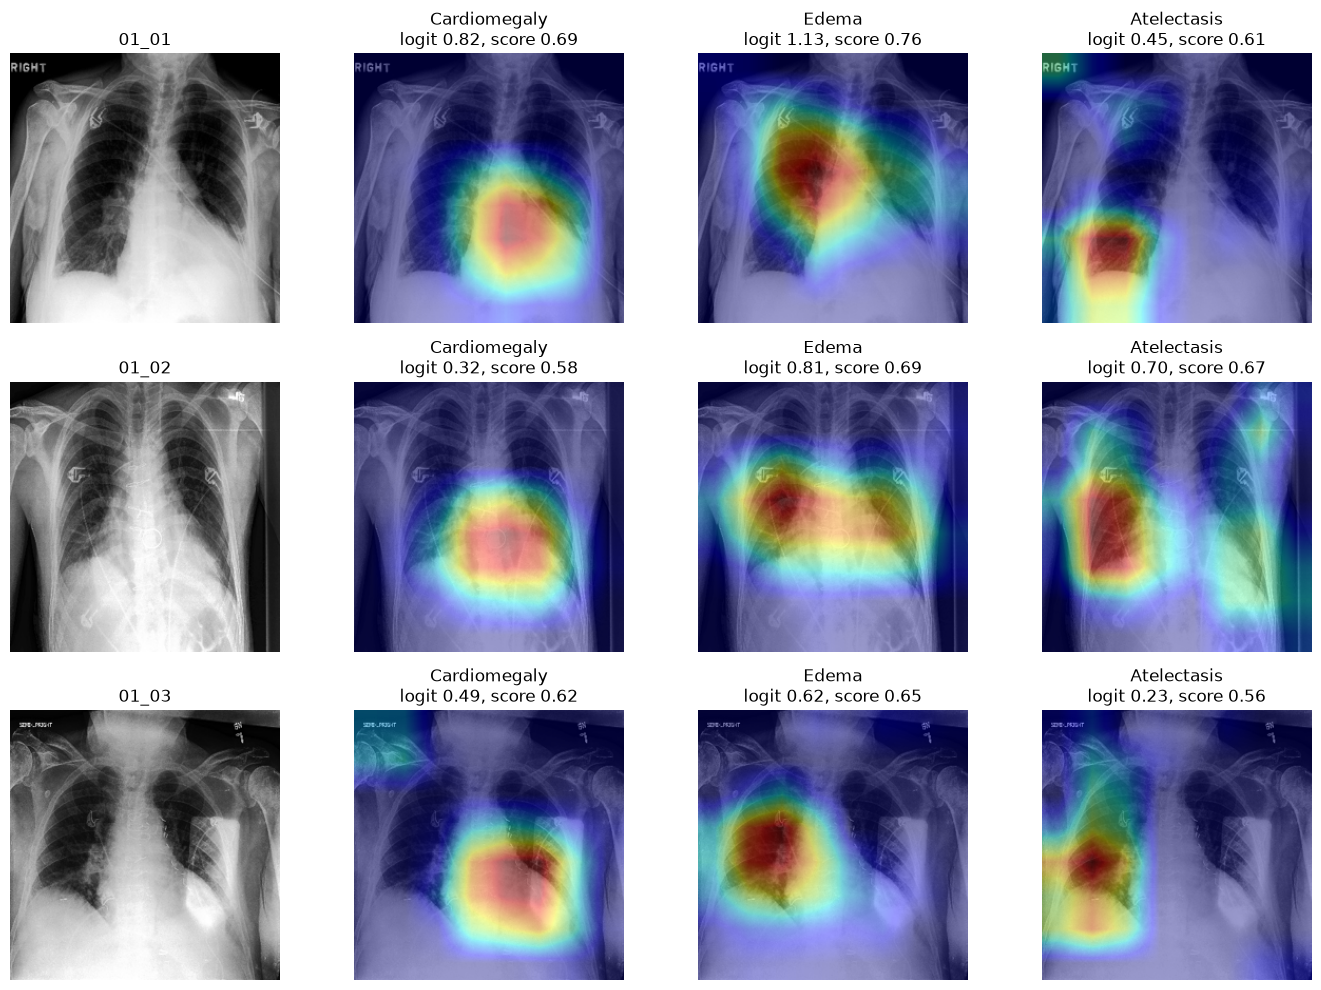

In [14]:

import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from PIL import Image
from load_model import load_model, preprocess

def gradcam(model, x):
    # Same forward pass as DenseNet.forward, but with a non-inplace ReLU so autograd can
    # take gradients at the last feature layer (norm5). torchvision's forward uses inplace=True.
    f = model.features(x)                                  # norm5 output
    f.retain_grad()
    out = F.relu(f)
    out = torch.flatten(F.adaptive_avg_pool2d(out, 1), 1)
    logit = model.classifier(out)[0, 0]                    # positive logit, no softmax
    model.zero_grad()
    logit.backward()
    w = f.grad.mean(dim=(2, 3), keepdim=True)              # one weight per channel
    cam = F.relu((w * f).sum(1, keepdim=True))             # weighted sum + ReLU
    cam = F.interpolate(cam, size=(256, 256), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return logit.item(), cam.detach().numpy()

targets = ["Cardiomegaly", "Edema", "Atelectasis"]
models = {t: load_model(t) for t in targets}
imgs = ["01_01", "01_02", "01_03"]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for r, iid in enumerate(imgs):
    img = Image.open(f"images/01_compare_models/{iid}_original.jpg").convert("RGB")
    x = preprocess(img)
    show = np.asarray(img.resize((256, 256)))
    axes[r, 0].imshow(show); axes[r, 0].set_title(iid)
    for c, t in enumerate(targets, start=1):
        m = models[t]
        logit, cam = gradcam(m, x)       # last feature layer
        axes[r, c].imshow(show); axes[r, c].imshow(cam, cmap="jet", alpha=0.4)
        axes[r, c].set_title(f"{t}\nlogit {logit:.2f}, score {torch.sigmoid(torch.tensor(logit)):.2f}")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

## test 2

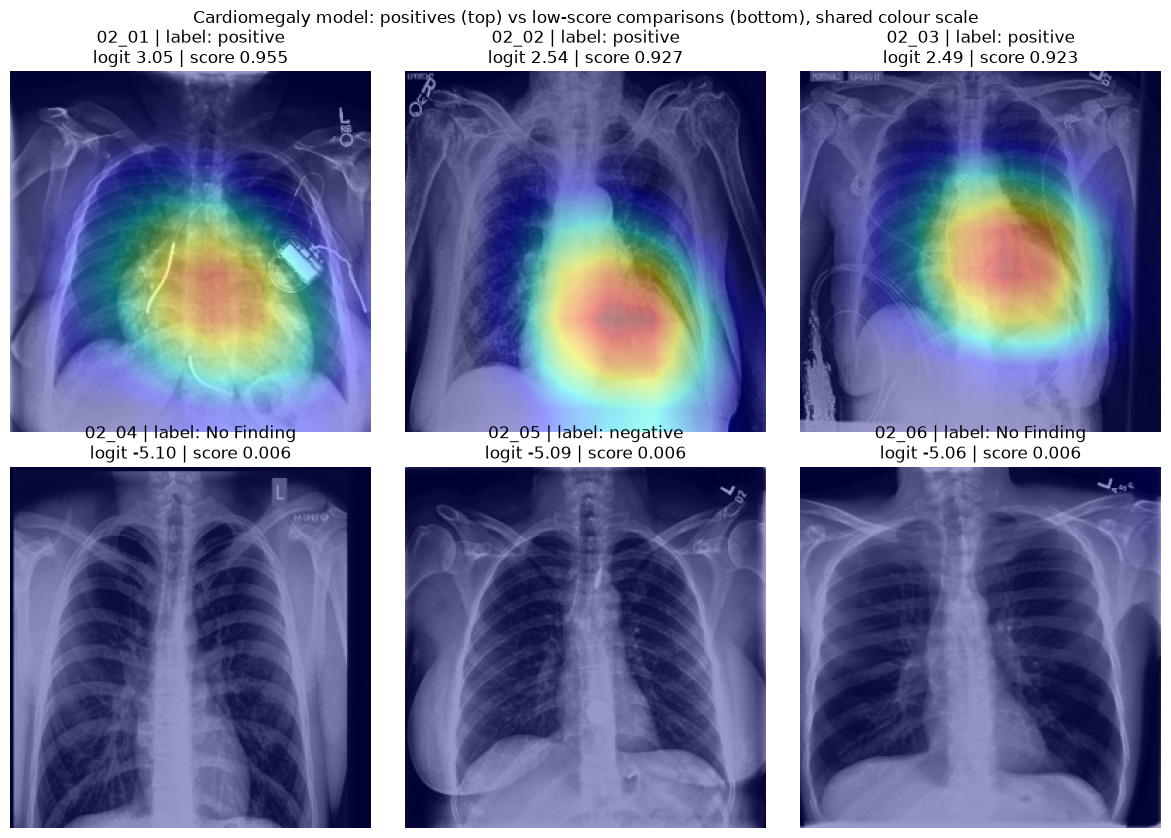

            label     logit     score
02_01    positive  3.045968  0.954608
02_02    positive  2.540903   0.92696
02_03    positive  2.490174   0.92345
02_04  No Finding -5.098258   0.00607
02_05    negative -5.091095  0.006114
02_06  No Finding -5.062474   0.00629


In [15]:
import numpy as np, pandas as pd, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from PIL import Image
from load_model import load_model, preprocess

model = load_model("Cardiomegaly")
meta = pd.read_csv("images.csv").set_index("image_id")

def gradcam_raw(model, x):
    # Same forward pass as DenseNet.forward, with a non-inplace ReLU (see gradcam above).
    f = model.features(x)                                  # norm5 output
    f.retain_grad()
    out = torch.flatten(F.adaptive_avg_pool2d(F.relu(f), 1), 1)
    logit = model.classifier(out)[0, 0]
    model.zero_grad()
    logit.backward()
    w = f.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * f).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(256, 256), mode="bilinear", align_corners=False)[0, 0]
    return logit.item(), cam.detach().numpy()          # NOT normalised

def label_text(iid):
    row = meta.loc[f"{iid}_original"]
    if row["No Finding"] == 1: return "No Finding"
    v = row["Cardiomegaly"]
    return {1.0: "positive", 0.0: "negative", -1.0: "uncertain"}.get(v, "blank")

ids = [f"02_0{i}" for i in range(1, 7)]
results = {}
for iid in ids:
    img = Image.open(f"images/02_positive_negative/{iid}_original.jpg").convert("RGB")
    logit, cam = gradcam_raw(model, preprocess(img))
    results[iid] = dict(img=np.asarray(img.resize((256, 256))), logit=logit,
                        score=torch.sigmoid(torch.tensor(logit)).item(), cam=cam)

vmax = max(r["cam"].max() for r in results.values())   # one shared colour scale

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5))
for ax, iid in zip(axes.flat, ids):
    r = results[iid]
    ax.imshow(r["img"]); ax.imshow(r["cam"], cmap="jet", alpha=0.4, vmin=0, vmax=vmax)
    ax.set_title(f"{iid} | label: {label_text(iid)}\nlogit {r['logit']:.2f} | score {r['score']:.3f}")
    ax.axis("off")
fig.suptitle("Cardiomegaly model: positives (top) vs low-score comparisons (bottom), shared colour scale")
plt.tight_layout(); plt.show()

print(pd.DataFrame({k: {"label": label_text(k), "logit": v["logit"], "score": v["score"]}
                    for k, v in results.items()}).T.round(3))

### Step 3

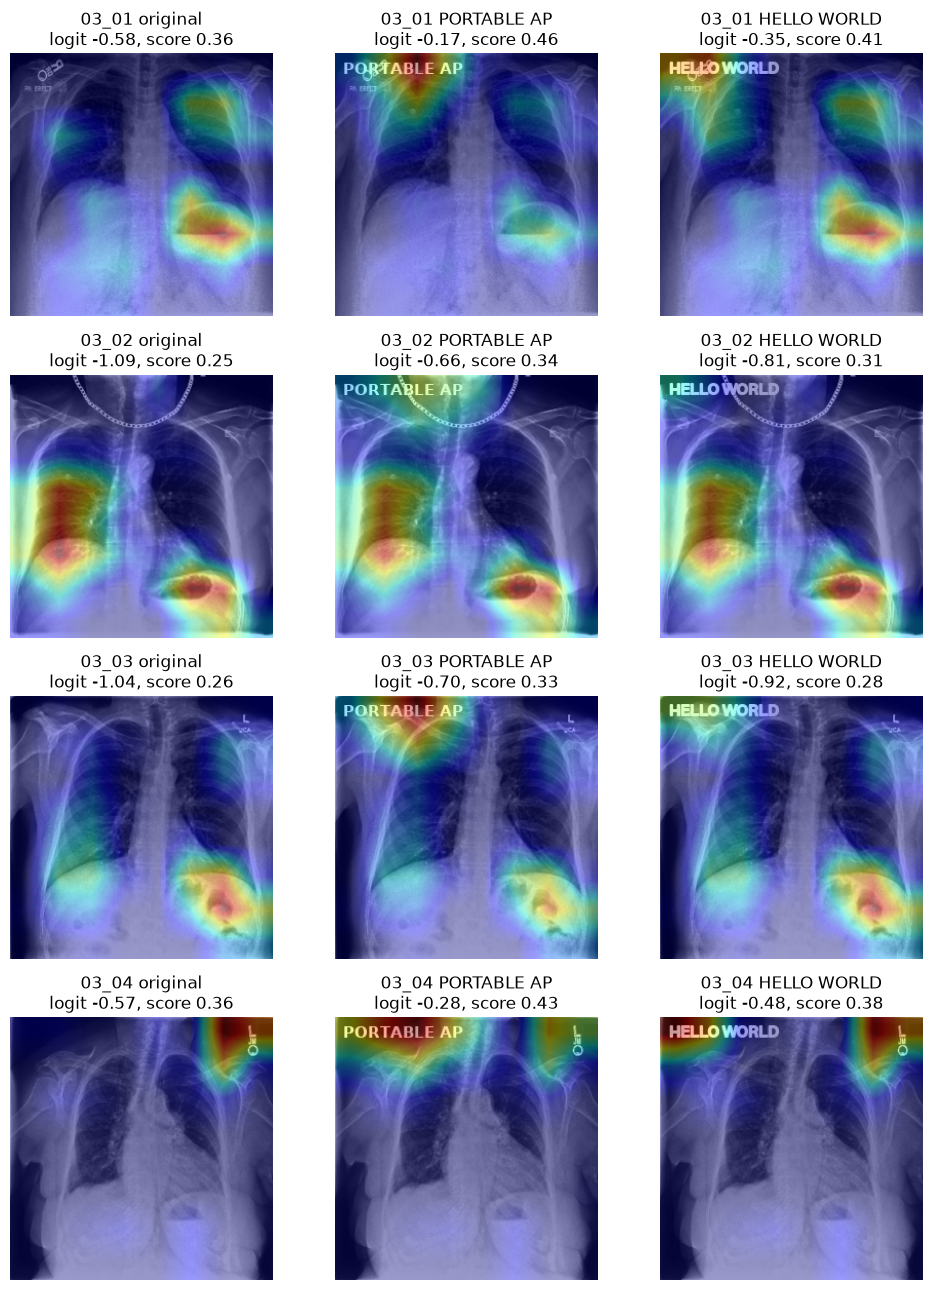

version  HELLO WORLD  PORTABLE AP  original  Δ PORTABLE AP  Δ HELLO WORLD
image                                                                    
03_01          0.414        0.458     0.359          0.099          0.055
03_02          0.308        0.341     0.252          0.089          0.056
03_03          0.284        0.331     0.262          0.069          0.022
03_04          0.383        0.431     0.362          0.069          0.021
version  HELLO WORLD  PORTABLE AP  original  Δ logit PORTABLE AP  \
image                                                              
03_01         -0.348       -0.170    -0.581                0.411   
03_02         -0.811       -0.658    -1.089                0.431   
03_03         -0.924       -0.704    -1.036                0.333   
03_04         -0.476       -0.279    -0.567                0.289   

version  Δ logit HELLO WORLD  
image                         
03_01                  0.233  
03_02                  0.278  
03_03                  

In [16]:
from PIL import Image, ImageDraw, ImageFont
import numpy as np, torch, matplotlib.pyplot as plt
from load_model import load_model, preprocess

model = load_model("Atelectasis")
font = ImageFont.load_default(size=15)

def add_text(img, text):
    img = img.copy()
    d = ImageDraw.Draw(img)
    bb = d.textbbox((0, 0), text, font=font)
    d.text((9 - bb[0], 9 - bb[1]), text, font=font, fill="white", stroke_width=1, stroke_fill="white")
    return img

rows = []
fig, axes = plt.subplots(4, 3, figsize=(10, 13))
for r, k in enumerate(["03_01", "03_02", "03_03", "03_04"]):
    orig = Image.open(f"images/03_text_shortcut/{k}_original.jpg").convert("RGB").resize((256, 256), Image.Resampling.BILINEAR)
    versions = {
        "original":    orig,
        "PORTABLE AP": Image.open(f"images/03_text_shortcut/{k}_text.png").convert("RGB"),
        "HELLO WORLD": add_text(orig, "HELLO WORLD"),          # control
    }
    for c, (name, img) in enumerate(versions.items()):
        logit, cam = gradcam(model, preprocess(img))
        score = torch.sigmoid(torch.tensor(logit)).item()
        rows.append({"image": k, "version": name, "logit": logit, "score": score})
        axes[r, c].imshow(np.asarray(img)); axes[r, c].imshow(cam, cmap="jet", alpha=0.4)
        label = "positive" if logit > 0 else "negative"     # same as score >= 0.5
        axes[r, c].set_title(f"{k} {name}\nlogit {logit:.2f}, score {score:.2f}")
        axes[r, c].axis("off")
plt.tight_layout(); plt.show()

import pandas as pd
res = pd.DataFrame(rows).pivot(index="image", columns="version", values="score")
res["Δ PORTABLE AP"] = res["PORTABLE AP"] - res["original"]
res["Δ HELLO WORLD"] = res["HELLO WORLD"] - res["original"]
print(res.round(3))

logits = pd.DataFrame(rows).pivot(index="image", columns="version", values="logit")
logits["Δ logit PORTABLE AP"] = logits["PORTABLE AP"] - logits["original"]
logits["Δ logit HELLO WORLD"] = logits["HELLO WORLD"] - logits["original"]
print(logits.round(3))

In [17]:
113/333

0.33933933933933935

## Step 4

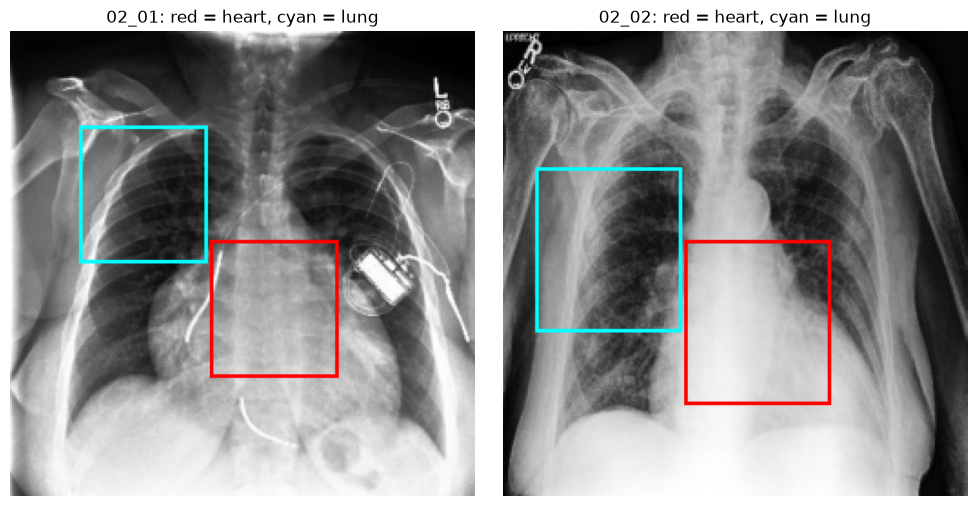

In [18]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

boxes = {
    "02_01": {"heart": (110, 115, 180, 190), "lung": (38, 52, 108, 127)},
    "02_02": {"heart": (100, 115, 180, 205), "lung": (18, 75, 98, 165)},
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, k in zip(axes, boxes):
    img = Image.open(f"images/02_positive_negative/{k}_original.jpg").convert("RGB").resize((256, 256), Image.Resampling.BILINEAR)
    d = ImageDraw.Draw(img)
    d.rectangle(boxes[k]["heart"], outline="red", width=2)     # heart box
    d.rectangle(boxes[k]["lung"], outline="cyan", width=2)     # lung control
    ax.imshow(img); ax.set_title(f"{k}: red = heart, cyan = lung"); ax.axis("off")
plt.tight_layout(); plt.show()

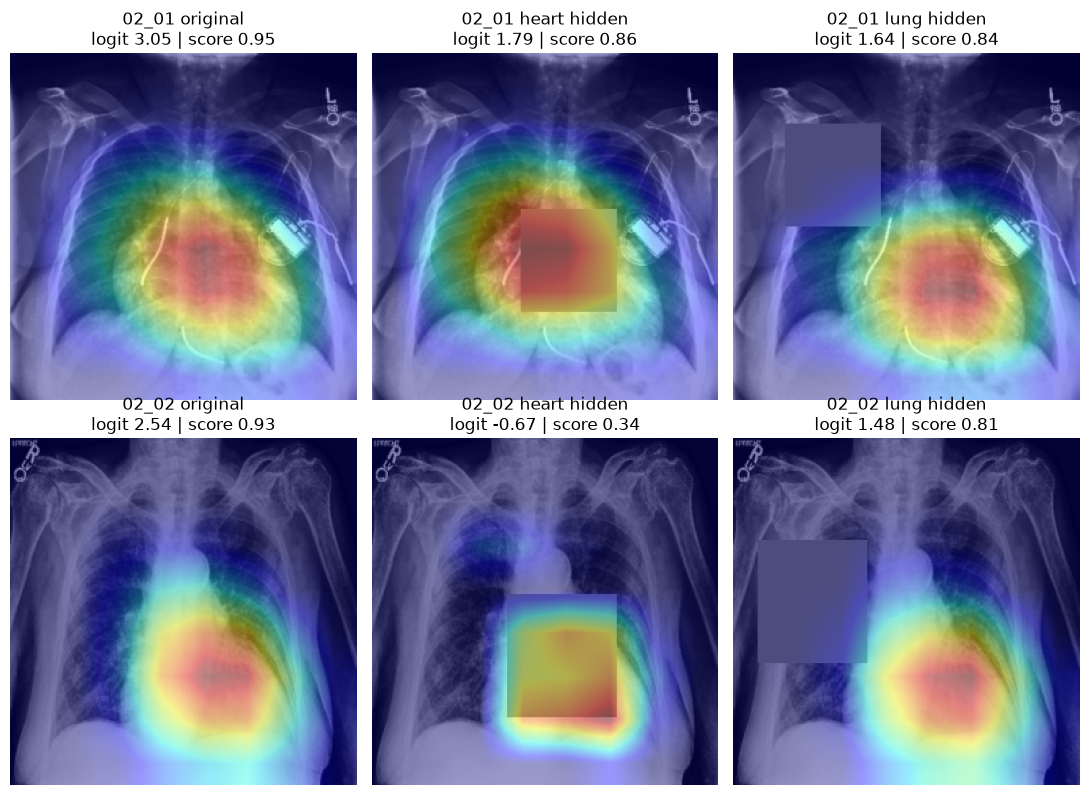

In [19]:
from PIL import Image, ImageDraw
import numpy as np, torch, matplotlib.pyplot as plt
from load_model import load_model, preprocess

model = load_model("Cardiomegaly")

# (x0, y0, x1, y1) on the 256x256 image; adjust after looking at the first plot
boxes = {
    "02_01": {"heart": (110, 115, 180, 190), "lung": (38, 52, 108, 127)},
    "02_02": {"heart": (100, 115, 180, 205), "lung": (18, 75, 98, 165)},
}
def occlude(img, box, fill=(128, 128, 128)):        # edit BEFORE preprocess/normalisation
    img = img.copy(); ImageDraw.Draw(img).rectangle(box, fill=fill); return img

fig, axes = plt.subplots(2, 3, figsize=(11, 8))
for r, k in enumerate(boxes):
    orig = Image.open(f"images/02_positive_negative/{k}_original.jpg").convert("RGB").resize((256, 256), Image.Resampling.BILINEAR)
    versions = {"original": orig,
                "heart hidden": occlude(orig, boxes[k]["heart"]),
                "lung hidden":  occlude(orig, boxes[k]["lung"])}
    for c, (name, img) in enumerate(versions.items()):
        logit, cam = gradcam(model, preprocess(img))
        score = torch.sigmoid(torch.tensor(logit)).item()
        axes[r, c].imshow(np.asarray(img)); axes[r, c].imshow(cam, cmap="jet", alpha=0.4)
        axes[r, c].set_title(f"{k} {name}\nlogit {logit:.2f} | score {score:.2f}"); axes[r, c].axis("off")
plt.tight_layout(); plt.show()